# Overfitting and the train/test split

A model is useful for the data it has *not* seen: the next employee's salary, next month's house prices. Its error on the data it learned from says little about that. The [decision tree](../algorithms/tree-based/decision_trees.ipynb) ended with a model that passes through almost every training point: its error on those points is close to zero, and yet it would be a poor guess of anyone else's salary. Measuring that gap needs data the model never saw.

## The data

The simulated salaries of [Linear regression](../algorithms/linear-models/linear_regression.ipynb), generated the same way for 140 employees instead of 30, so that some of them can be held back: one row per employee, years of experience as the only feature and the salary as the target.

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=140).round(2)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=140)
salaries = pd.DataFrame({"YearsExperience": years, "Salary": salary.round(-2)})
salaries.shape

(140, 2)

In [ ]:
X = salaries[["YearsExperience"]]
y = salaries["Salary"]

A small function draws the training rows, the test rows and a model's predictions, so that each model below can be seen against the data:

In [ ]:
import matplotlib.pyplot as plt


def plot_regression(X_train, y_train, X_test=None, y_test=None, model=None, label="Training rows"):
    plt.scatter(X_train, y_train, color="tab:blue", label=label)
    if X_test is not None:
        plt.scatter(X_test, y_test, color="tab:orange", label="Test rows")
    if model is not None:
        grid = pd.DataFrame({"YearsExperience": np.linspace(X_train.min(), X_train.max(), num=500).ravel()})
        plt.plot(grid, model.predict(grid), color="tab:red", label="Model")
    plt.xlabel("Years of experience")
    plt.ylabel("Salary")
    plt.legend()
    plt.show()

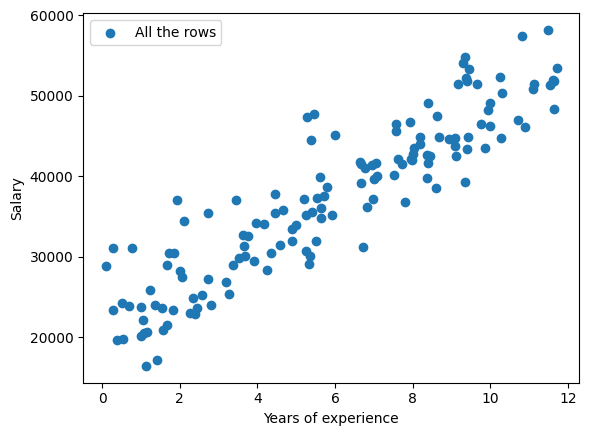

In [ ]:
plot_regression(X, y, label="All the rows")

## Holding data back

The rows are split in two. The model learns from the **training set**; its error is then measured on the **test set**, rows it never saw. A model whose error is low on the training set and high on the test set has learned the training rows rather than the relationship between experience and salary: it **overfits**.

Two sets are enough to measure one model. Choosing *between* models will need a third, the **validation set**, so that the test set is used only once, at the end: [Validation and model selection](validation_and_model_selection.ipynb) explains why.

scikit-learn's `train_test_split` makes the split: it shuffles the rows at random and cuts them in two, the features and the target in one call. The shuffle is random, so two calls draw different test rows, and each would measure a different error:

In [ ]:
from sklearn.model_selection import train_test_split

first_test_rows = train_test_split(X, y, test_size=0.2)[1].index
second_test_rows = train_test_split(X, y, test_size=0.2)[1].index
first_test_rows.equals(second_test_rows)

False

A fixed **seed**, the argument `random_state`, makes the shuffle the same every time, and so the split:

In [ ]:
first_test_rows = train_test_split(X, y, test_size=0.2, random_state=42)[1].index
second_test_rows = train_test_split(X, y, test_size=0.2, random_state=42)[1].index
first_test_rows.equals(second_test_rows)

True

Fixing the seed makes a result reproducible: two models compared on the same rows, a bug that appears again when the code runs again, a result someone else can check. It doesn't make the split any better: 42 is a convention, not a choice.

The split used in the rest of this notebook:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((112, 1), (28, 1))

Holding back 20% is a common default. What makes a test error precise is the number of test rows, not their share of the data: with a hundred thousand rows, 2% is already two thousand rows; with the 140 rows here, 20% is only 28, and the test error moves noticeably from one split to another.

## A linear model and a tree on the same split

Both models learn from the training rows only. Their error is the mean absolute error (MAE) of [linear regression](../algorithms/linear-models/linear_regression.ipynb): the average distance between the predicted and the true salary, in the salary's own units. It is measured on both sets, to compare them:

In [ ]:
from sklearn.metrics import mean_absolute_error

def train_and_test_error(model):
    return pd.Series({
        "training MAE": mean_absolute_error(y_train, model.predict(X_train)),
        "test MAE": mean_absolute_error(y_test, model.predict(X_test)),
    }).round()

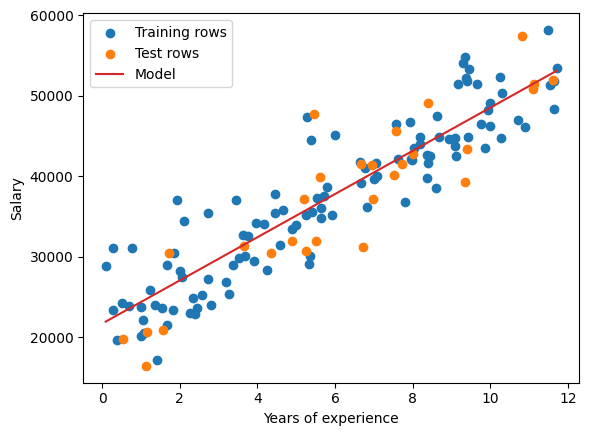

In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression().fit(X_train, y_train)
plot_regression(X_train, y_train, X_test, y_test, linear_model)

In [ ]:
train_and_test_error(linear_model)

training MAE    3147.0
test MAE        3647.0
dtype: float64

The line misses the true salary by about 3,100 on the training rows and 3,600 on the test rows. The test error is a little higher, as it usually is on rows the model never saw, and with only 28 test rows part of the difference is the luck of which rows landed in the test set. What matters is that there is no large gap: the line does about as well on rows it never saw as on the rows it learned from.

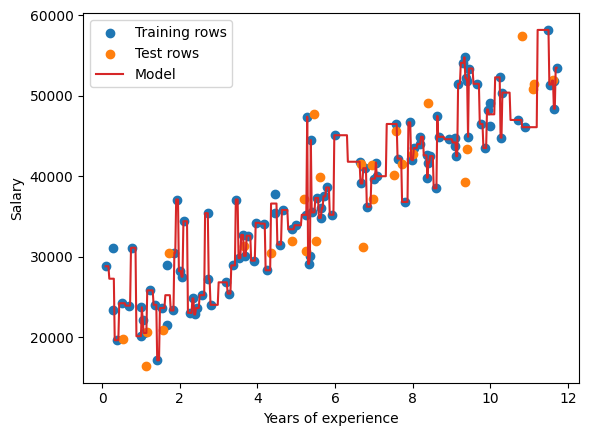

In [ ]:
from sklearn.tree import DecisionTreeRegressor

unlimited_tree = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
plot_regression(X_train, y_train, X_test, y_test, unlimited_tree)

In [ ]:
train_and_test_error(unlimited_tree)

training MAE     190.0
test MAE        4675.0
dtype: float64

The tree without limits has almost no error on its training rows: about 190, against the line's 3,147. It isn't exactly zero only because a few employees share the same years of experience with different salaries, and a tree gives a single prediction for each value. On the test rows its error is about 4,700, worse than the straight line's 3,647. The plot shows why: the prediction jumps up and down to reach each training point, and those jumps follow the noise of these particular employees, not a pattern that new ones will follow. A low training error with a much higher test error is **overfitting**, and only the test set could reveal it.

A tree overfits so easily, and a straight line doesn't, because of what each one is allowed to be:

- A **parametric** model, such as linear regression, has a fixed form with a fixed number of parameters. A line stays a line however many rows it learns from, so it cannot bend towards each point.
- A **non-parametric** model, such as a decision tree, grows with the data: the more rows, the more splits it can make. Unless something limits it, it can fit every training row.

Flexibility is not a defect: the relationship to learn is rarely a straight line. It has to be limited, and the test error shows how much.

## Underfitting and overfitting

The depth of a tree is the largest number of questions it asks before it predicts: depth 1 splits the rows once, depth 2 splits each half again, and so on. Measuring both errors for each depth shows the whole range, from too simple to too flexible:

In [ ]:
depths = range(1, 11)
errors_by_depth = pd.DataFrame(
    {depth: train_and_test_error(DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train, y_train))
     for depth in depths}
).T.rename_axis("max_depth")
errors_by_depth

,training MAE,test MAE
max_depth,,
1,4573.0,5719.0
2,3179.0,4277.0
3,2693.0,4453.0
4,2184.0,4402.0
5,1706.0,4471.0
6,1178.0,4550.0
7,875.0,4579.0
8,618.0,4744.0
9,426.0,4668.0


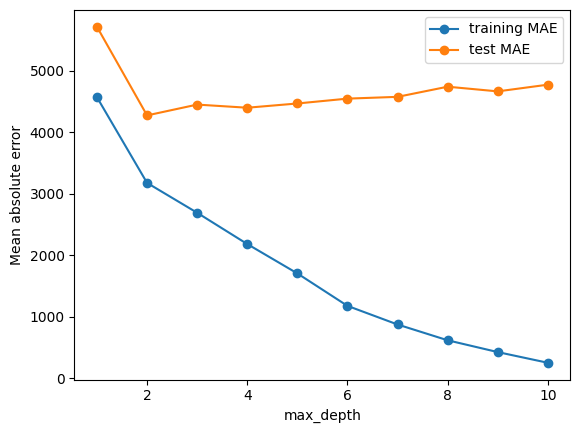

In [ ]:
errors_by_depth.plot(marker="o")
plt.ylabel("Mean absolute error")
plt.show()

At depth 1 both errors are high, about 4,600 on the training rows and 5,700 on the test rows: one question is not enough to describe how salary grows with experience. As the depth grows, the training error keeps falling, down to about 250 at depth 10, because each new level fits the training rows more closely. The test error falls only until depth 2, to about 4,300, and then rises again, unevenly: from there on, the extra splits fit the noise of the training rows. The depth with the lowest test error:

In [ ]:
best_depth = errors_by_depth["test MAE"].idxmin()
best_depth

2

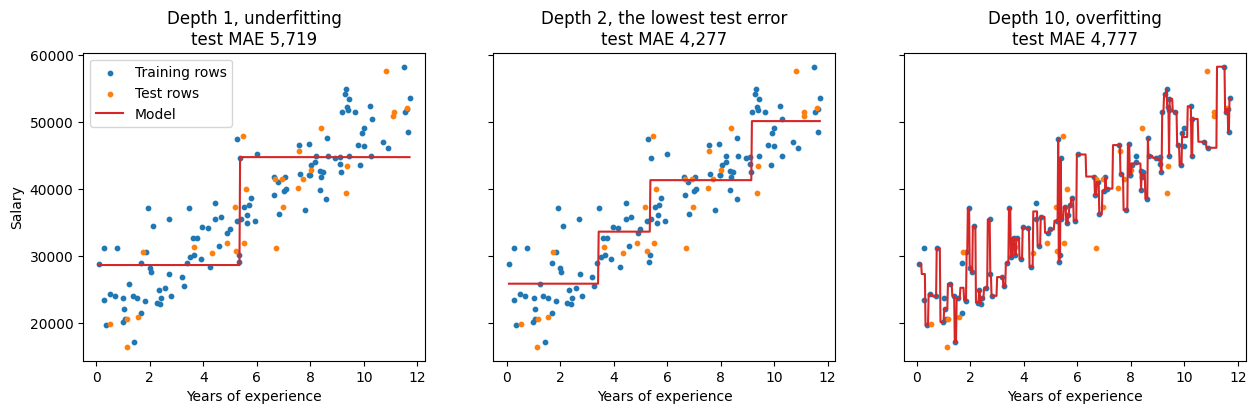

In [ ]:
grid = pd.DataFrame({"YearsExperience": np.linspace(X_train.min(), X_train.max(), num=500).ravel()})
shown_depths = {1: "underfitting", best_depth: "the lowest test error", 10: "overfitting"}

figure, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for axis, (depth, description) in zip(axes, shown_depths.items()):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train, y_train)
    axis.scatter(X_train, y_train, color="tab:blue", s=10, label="Training rows")
    axis.scatter(X_test, y_test, color="tab:orange", s=10, label="Test rows")
    axis.plot(grid, tree.predict(grid), color="tab:red", label="Model")
    axis.set_title(f"Depth {depth}, {description}\ntest MAE {errors_by_depth.loc[depth, 'test MAE']:,.0f}")
    axis.set_xlabel("Years of experience")
axes[0].set_ylabel("Salary")
axes[0].legend()
plt.show()

Even at its best depth, the tree (about 4,300) does not beat the straight line (about 3,650). Salary grows linearly with experience here, because that is how the data were simulated: a line describes it with two parameters, and a tree can only approximate it with steps. The most flexible model is not the best one; the one whose form suits the data is.

The two ends of the curve and the point between them have names, the titles of the three panels above:

- **Underfitting:** the model is too simple to capture the relationship. The error is high on both sets. Its errors are systematic: trained on other rows, it would make the same ones, a high *bias*.
- **Overfitting:** the model is flexible enough to fit the noise of its training rows. The training error is low and the test error high. Trained on other rows, it would be a different model, a high *variance*.
- **A good fit** sits between them: the lowest error on data the model didn't see.

One warning about the depth chosen above. It was chosen by looking at the test error, so the test set has stopped being data the model's design never saw: the test error of the chosen depth is now slightly optimistic. Here the test set plays two roles only to show the shape of the curve. Choosing a model honestly needs a third set, the validation set, or cross-validation: [Validation and model selection](validation_and_model_selection.ipynb) and [Cross-validation and hyperparameter search](cross_validation_and_search.ipynb).

## Stratified splits

A random split is representative *on average*. With few rows, or with groups that matter and are rare, one particular draw can leave the test set with too many or too few rows of a group, and its error then describes the wrong mix of cases: a **sampling bias**. A **stratified** split avoids it: the rows are divided into groups (*strata*), and each group is split in the same proportion.

The iris flowers of [Decision trees](../algorithms/tree-based/decision_trees.ipynb) show it: 150 flowers, 50 of each of three species. A test set of 20%, 30 flowers, should hold 10 of each. How many of each species six random splits put in their test sets:

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
species = iris.target.map(dict(enumerate(iris.target_names))).rename("species")
pd.DataFrame({
    f"seed {seed}": train_test_split(species, test_size=0.2, random_state=seed)[1].value_counts()
    for seed in range(6)
})

,seed 0,seed 1,seed 2,seed 3,seed 4,seed 5
species,,,,,,
setosa,11,11,14,10,16,8
versicolor,13,13,8,10,5,11
virginica,6,6,8,10,9,11


Some of these test sets are far from 10 of each: seed 4 puts 16 setosa flowers in the test set and only 5 versicolor, so an error measured on it would mostly describe setosa. `stratify=` tells `train_test_split` which groups to keep in proportion:

In [ ]:
pd.DataFrame({
    f"seed {seed}": train_test_split(species, test_size=0.2, stratify=species, random_state=seed)[1].value_counts()
    for seed in range(6)
})

,seed 0,seed 1,seed 2,seed 3,seed 4,seed 5
species,,,,,,
setosa,10,10,10,10,10,10
versicolor,10,10,10,10,10,10
virginica,10,10,10,10,10,10


Every stratified test set holds exactly 10 flowers of each species, whatever the seed.

In classification, as here, the usual strata are the classes: `stratify=y` keeps the proportion of each class, which matters most when a class is rare. In regression the target is a number, so the rows are first cut into bands, of the target itself or of a strong predictor: the California housing worked example [stratifies its districts by bands of median income](https://github.com/avidaldo/california_e2e/blob/master/notes/stratified_sampling.ipynb), their strongest predictor. Neither is a leak: the groups only decide which rows go to each side, and the model learns nothing from the test rows.

## The test set stands for production

The split is a simulation. A model is trained once and then used on rows that arrive later, which it has never seen; the test set plays the part of those rows. Its error estimates the error in production **only as far as the test rows resemble what production will bring**. So the question that decides how to split is what production will bring:

| What the model will meet | How to split |
| --- | --- |
| New rows like the old ones, in no particular order | At random |
| Few rows, or groups that matter and a random draw could miss | Stratified |
| The future, predicted from the past | By time: learn from the earlier rows, test on the later ones ([King County: temporal leakage](https://github.com/avidaldo/king-county/blob/master/03-temporal_leakage.ipynb)) |
| Entities that appear more than once: a patient, a house sold twice | By group: all the rows of an entity on the same side ([King County: repeated identifiers](https://github.com/avidaldo/king-county/blob/master/02-repeated_ids.ipynb)) |

No split anticipates a world that changes after the model is trained (*drift*): that is watched once the model is in use, not estimated before.

Two consequences follow, and the rest of this topic applies them:

- **Whatever is learned from data is learned from the training rows only, and applied unchanged to new rows.** A scaler's mean and spread, a median that fills gaps, the list of categories of an encoder: in production they exist before the new row arrives, so they cannot depend on it. [California housing, step by step](../basic-workflows/california_by_hand.ipynb) does it by hand; a pipeline does it for every step at once ([California housing with pipelines](../basic-workflows/california_with_pipelines.ipynb)).
- **An input must exist at the moment of prediction.** A column computed from the target, or recorded after the event being predicted, may be in the table, but it won't be there when the model is used. A model that learns from it scores well on the test set and fails in production: [Data leakage](data_leakage.ipynb).

## Further material

- [Dot CSV: ¿Aprenden o memorizan las redes neuronales? Overfitting y underfitting](https://www.youtube.com/watch?v=7-6X3DTt3R8) (video, in Spanish)
- [Afshine and Shervine Amidi: Machine learning tips and tricks](https://stanford.edu/~shervine/teaching/cs-229/cheatsheet-machine-learning-tips-and-tricks/): a cheatsheet whose table sums up underfitting and overfitting, with their symptoms and remedies